# Fase C: Modelos supervisados para hospitalización por dengue

**Variable objetivo:** `PAC_HOS` (`1` = hospitalización registrada, `2` = no hospitalización)

## Pregunta de negocio
¿Qué tan bien puede anticiparse, a partir de la información disponible en el registro de notificación, si un caso tendrá hospitalización registrada? El resultado sirve para priorizar revisión y vigilancia, pero no sustituye una decisión clínica.

## Alcance y decisiones
Se comparan Regresión Logística, Árbol de Decisión y Random Forest. El conjunto de prueba se separa antes de ajustar cualquier imputador, codificador, escalador o modelo. `AJUSTE` se excluye porque puede ser un campo posterior a la notificación; `nom_est_f_caso` se excluye por su alta cardinalidad y posible relación con el resultado; municipio se excluye para evitar una representación demasiado dispersa y dependiente del territorio. La clase positiva es hospitalización. Para atender el desbalance aproximado 38/62 se usa `class_weight`, que asigna un peso mayor a la clase minoritaria y evita que el modelo favorezca excesivamente la clase mayoritaria.

Los resultados describen asociaciones y capacidad predictiva dentro de este conjunto de registros. No son tasas poblacionales ni prueban causalidad; el AUC esperado es moderado y debe validarse con datos nuevos.

In [15]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
    precision_score, precision_recall_curve, recall_score, roc_auc_score, roc_curve,
    classification_report)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42
TARGET = "hospitalizado"
pd.set_option("display.max_columns", 100)

## 1. Carga y control de calidad

Se busca primero el parquet limpio de la Fase B y, si todavía no existe, se utiliza el consolidado del P1. Esto permite ejecutar la Fase C de forma independiente durante la revisión, sin ocultar cuál es el origen real de los datos.

In [16]:
rutas_limpias = (
    Path.cwd() / "datos_limpios.parquet",
    Path.cwd().parent / "datos_limpios.parquet",
)
rutas_crudas = (
    Path.cwd() / "datos" / "procesados" / "dengue_consolidado.parquet",
    Path.cwd().parent / "datos" / "procesados" / "dengue_consolidado.parquet",
)
ruta_parquet = next((p for p in rutas_limpias if p.exists()), None)
origen = "datos_limpios.parquet"
if ruta_parquet is None:
    ruta_parquet = next((p for p in rutas_crudas if p.exists()), None)
    origen = "dengue_consolidado.parquet"
if ruta_parquet is None:
    raise FileNotFoundError("No se encontro datos_limpios.parquet ni dengue_consolidado.parquet.")

df = pd.read_parquet(ruta_parquet).copy()
columnas_minimas = {"PAC_HOS", "EDAD", "UNI_MED", "ANO", "SEMANA"}
faltantes = columnas_minimas - set(df.columns)
if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {sorted(faltantes)}")

print(f"Origen: {ruta_parquet.resolve()} ({origen})")
print(f"Registros leidos: {len(df):,}")
display(df.head(3))

Origen: C:\Users\Sanatiago Hernadez\Desktop\grupo-4-p1\datos\procesados\dengue_consolidado.parquet (dengue_consolidado.parquet)
Registros leidos: 581,071


,SEMANA,ANO,EDAD,UNI_MED,SEXO,COD_DPTO_O,COD_MUN_O,AREA,TIP_SS,PER_ETN,estrato,GP_DESPLAZ,GP_MIGRANT,GP_GESTAN,TIP_CAS,PAC_HOS,AJUSTE,nom_est_f_caso,Departamento_ocurrencia,Municipio_ocurrencia
0,11,2022,6,1,M,44,1,1,S,6,2,2,2,2,3,1,0,Confirmado por laboratorio,GUAJIRA,RIOHACHA
1,33,2022,37,1,M,54,1,1,C,6,1,2,2,2,3,1,0,Confirmado por laboratorio,NORTE SANTANDER,CUCUTA
2,16,2022,10,1,M,20,750,1,S,6,1,2,2,2,2,1,3,Confirmado por laboratorio,CESAR,SAN DIEGO


In [17]:
# Normalizacion del objetivo sin modificar el parquet original.
pac_hos = pd.to_numeric(df["PAC_HOS"], errors="coerce")
df = df.loc[pac_hos.isin([1, 2])].copy()
df[TARGET] = (pd.to_numeric(df["PAC_HOS"], errors="coerce") == 1).astype("int8")

# Edad en anos: UNI_MED=1 representa anos; las demas unidades corresponden
# a edades inferiores a un ano y se conservan como 0 anos para modelar.
edad = pd.to_numeric(df["EDAD"], errors="coerce")
unidad = pd.to_numeric(df["UNI_MED"], errors="coerce")
df["edad_anios"] = np.where(unidad.eq(1), edad, 0.0)
df.loc[~df["edad_anios"].between(0, 100), "edad_anios"] = np.nan

print("Distribucion de la variable objetivo:")
tabla_objetivo = df[TARGET].value_counts().rename(index={0: "No hospitalizado", 1: "Hospitalizado"}).to_frame("registros")
tabla_objetivo["porcentaje"] = 100 * tabla_objetivo["registros"] / len(df)
display(tabla_objetivo)
assert df[TARGET].nunique() == 2
assert df["edad_anios"].dropna().between(0, 100).all()

Distribucion de la variable objetivo:


,registros,porcentaje
hospitalizado,,
No hospitalizado,357711,61.560635
Hospitalizado,223360,38.439365


**Control de calidad:** los valores de edad mayores de 100 años se convierten en faltantes y serán imputados dentro del pipeline. Esta decisión evita borrar registros completos por un error puntual y evita que el valor implausible influya en el ajuste.

## 2. División anti-leakage

La partición estratificada 80/20 se realiza antes de entrenar cualquier transformación. La estratificación conserva aproximadamente la misma proporción de hospitalizados en train y test. El test se toca únicamente en la evaluación final.

In [18]:
columnas_excluidas = ["PAC_HOS", TARGET, "AJUSTE", "nom_est_f_caso", "COD_MUN_O", "Municipio_ocurrencia", "EDAD", "UNI_MED"]
columnas_modelo = [c for c in df.columns if c not in columnas_excluidas]
X = df[columnas_modelo].copy()
y = df[TARGET].copy()
for columna in [c for c in ["ANO", "SEMANA", "edad_anios"] if c in X.columns]:
    X[columna] = pd.to_numeric(X[columna], errors="coerce")
for columna in [c for c in X.columns if c not in ["ANO", "SEMANA", "edad_anios"]]:
    X[columna] = X[columna].astype("string")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

indices_train = set(X_train.index)
indices_test = set(X_test.index)
assert indices_train.isdisjoint(indices_test)
assert len(indices_train | indices_test) == len(df)
print(f"Train: {len(X_train):,} filas | positivos: {y_train.mean():.3%}")
print(f"Test:  {len(X_test):,} filas | positivos: {y_test.mean():.3%}")
print("Verificacion anti-leakage: OK, no hay indices compartidos.")

Train: 464,856 filas | positivos: 38.439%
Test:  116,215 filas | positivos: 38.439%
Verificacion anti-leakage: OK, no hay indices compartidos.


## 3. Preprocesamiento reproducible

Las variables numéricas (`ANO`, `SEMANA`, `edad_anios`) se imputan con mediana y se estandarizan. Los códigos y categorías sin orden se imputan con moda y se codifican One-Hot. `estrato` se trata como ordinal, con categorías 1 a 6 y código `-1` para categorías desconocidas. Todos estos pasos viven dentro de cada `Pipeline`, por lo que `fit` solo ocurre sobre train durante la validación cruzada.

In [19]:
columnas_numericas = [c for c in ["ANO", "SEMANA", "edad_anios"] if c in X.columns]
columnas_ordinales = ["estrato"] if "estrato" in X.columns else []
columnas_categoricas = [c for c in X.columns if c not in columnas_numericas + columnas_ordinales]

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline([
            ("imputacion", SimpleImputer(strategy="median")),
            ("escalado", StandardScaler()),
        ]), columnas_numericas),
        ("ordinales", Pipeline([
            ("imputacion", SimpleImputer(strategy="most_frequent")),
            ("codificacion", OrdinalEncoder(categories=[["1", "2", "3", "4", "5", "6"]], handle_unknown="use_encoded_value", unknown_value=-1)),
        ]), columnas_ordinales),
        ("categoricas", Pipeline([
            ("imputacion", SimpleImputer(strategy="most_frequent")),
            ("codificacion", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), columnas_categoricas),
    ],
    remainder="drop",
)
print("Numericas:", columnas_numericas)
print("Ordinales:", columnas_ordinales)
print("Categoricas:", columnas_categoricas)
print("AJUSTE excluida:", "AJUSTE" not in X.columns)

Numericas: ['ANO', 'SEMANA', 'edad_anios']
Ordinales: ['estrato']
Categoricas: ['SEXO', 'COD_DPTO_O', 'AREA', 'TIP_SS', 'PER_ETN', 'GP_DESPLAZ', 'GP_MIGRANT', 'GP_GESTAN', 'TIP_CAS', 'Departamento_ocurrencia']
AJUSTE excluida: True


## 4. Entrenamiento y ajuste de hiperparámetros

La métrica de selección es ROC-AUC porque evalúa la capacidad de ordenar casos positivos y negativos en distintos umbrales. La validación cruzada de tres particiones ocurre únicamente dentro de `X_train`/`y_train`. `class_weight="balanced"` asigna un peso mayor a la clase minoritaria según su frecuencia. Así, los errores sobre los casos hospitalizados tienen mayor influencia durante el ajuste y se evita que Accuracy sea la única señal de calidad.

In [20]:
modelos = {
    "Regresion Logistica": (
        LogisticRegression(class_weight="balanced", max_iter=1000, solver="liblinear", random_state=RANDOM_STATE),
        {"modelo__C": [0.1, 1.0, 10.0]},
    ),
    "Arbol de Decision": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"modelo__max_depth": [5, 10, None], "modelo__min_samples_leaf": [10]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE),
        {"modelo__n_estimators": [50], "modelo__max_depth": [15], "modelo__min_samples_leaf": [1]},
    ),
}

ajustes = {}
for nombre, (modelo, parametros) in modelos.items():
    pipeline = Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])
    print(f"Iniciando {nombre}...")
    busqueda = GridSearchCV(
        pipeline, parametros, scoring="roc_auc", cv=3, n_jobs=-1, refit=True,
        return_train_score=False, verbose=2, pre_dispatch="2*n_jobs",
    )
    busqueda.fit(X_train, y_train)
    ajustes[nombre] = busqueda
    print(f"{nombre}: AUC CV={busqueda.best_score_:.4f} | parametros={busqueda.best_params_}")

assert set(ajustes) == set(modelos)

Iniciando Regresion Logistica...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Regresion Logistica: AUC CV=0.6672 | parametros={'modelo__C': 1.0}
Iniciando Arbol de Decision...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Arbol de Decision: AUC CV=0.6672 | parametros={'modelo__max_depth': 10, 'modelo__min_samples_leaf': 10}
Iniciando Random Forest...
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Random Forest: AUC CV=0.6932 | parametros={'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 50}


**Lectura metodológica:** el mejor AUC de validación cruzada no se interpreta como resultado final. La comparación válida se hará una sola vez sobre `X_test`, que no participó en la selección de hiperparámetros.

## 5. Evaluación final en test

Se reportan Accuracy, Precision, Recall, F1 y ROC-AUC. Precision indica qué proporción de las alertas de hospitalización fue correcta; Recall indica qué proporción de las hospitalizaciones registradas fue detectada; F1 equilibra ambas.

In [21]:
resultados = []
predicciones = {}
for nombre, busqueda in ajustes.items():
    modelo = busqueda.best_estimator_
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    predicciones[nombre] = {"pred": pred, "prob": prob}
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

tabla_metricas = pd.DataFrame(resultados).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(tabla_metricas.style.format({c: "{:.4f}" for c in tabla_metricas.columns if c != "Modelo"}))
for nombre, valores in predicciones.items():
    print(f"\n{nombre}\n", classification_report(y_test, valores["pred"], target_names=["No hospitalizado", "Hospitalizado"], digits=4, zero_division=0))

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.6462,0.5361,0.5915,0.5624,0.6900
1,Arbol de Decision,0.6303,0.5175,0.5631,0.5394,0.6634
2,Regresion Logistica,0.6232,0.5087,0.5751,0.5399,0.6630



Regresion Logistica
                   precision    recall  f1-score   support

No hospitalizado     0.7112    0.6532    0.6810     71543
   Hospitalizado     0.5087    0.5751    0.5399     44672

        accuracy                         0.6232    116215
       macro avg     0.6100    0.6142    0.6104    116215
    weighted avg     0.6334    0.6232    0.6267    116215


Arbol de Decision
                   precision    recall  f1-score   support

No hospitalizado     0.7113    0.6722    0.6912     71543
   Hospitalizado     0.5175    0.5631    0.5394     44672

        accuracy                         0.6303    116215
       macro avg     0.6144    0.6177    0.6153    116215
    weighted avg     0.6368    0.6303    0.6328    116215


Random Forest
                   precision    recall  f1-score   support

No hospitalizado     0.7273    0.6803    0.7031     71543
   Hospitalizado     0.5361    0.5915    0.5624     44672

        accuracy                         0.6462    116215
      

**Insight:** la tabla debe leerse priorizando la métrica alineada con el uso. Si el objetivo es no perder casos hospitalizados, Recall tiene prioridad; si los recursos de seguimiento son limitados, Precision gana importancia. Accuracy por sí sola puede ser engañosa ante el desbalance.

## 6. Matrices de confusión

La matriz muestra aciertos y errores en el umbral por defecto de 0.5. En un despliegue real el umbral debería elegirse con costos de falsos negativos y falsos positivos definidos por salud pública.

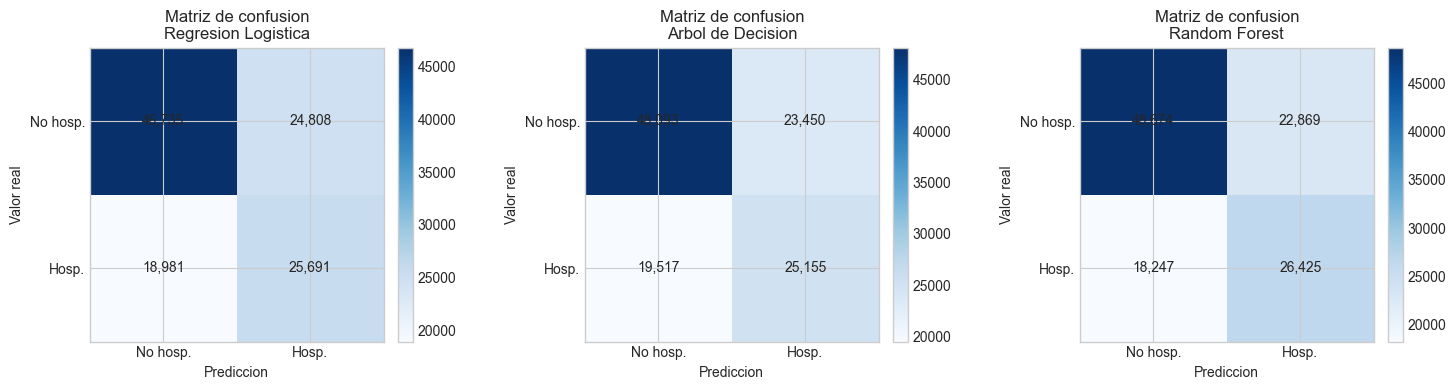

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, valores) in zip(axes, predicciones.items()):
    matriz = confusion_matrix(y_test, valores["pred"], labels=[0, 1])
    imagen = ax.imshow(matriz, cmap="Blues")
    ax.set_title(f"Matriz de confusion\n{nombre}")
    ax.set_xlabel("Prediccion")
    ax.set_ylabel("Valor real")
    ax.set_xticks([0, 1], ["No hosp.", "Hosp."])
    ax.set_yticks([0, 1], ["No hosp.", "Hosp."])
    for fila in range(2):
        for columna in range(2):
            ax.text(columna, fila, f"{matriz[fila, columna]:,}", ha="center", va="center")
    fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

**Insight:** los falsos negativos son registros hospitalizados clasificados como no hospitalizados y representan el error más sensible si el modelo se usa para priorizar seguimiento. La matriz permite decidir si conviene ajustar el umbral para aumentar Recall, aceptando posiblemente más falsas alarmas.

## 7. Curvas ROC comparativas

La curva ROC reúne todos los umbrales posibles. La línea diagonal representa un clasificador sin capacidad de discriminación; cuanto más arriba quede una curva, mejor separa los dos grupos en promedio.

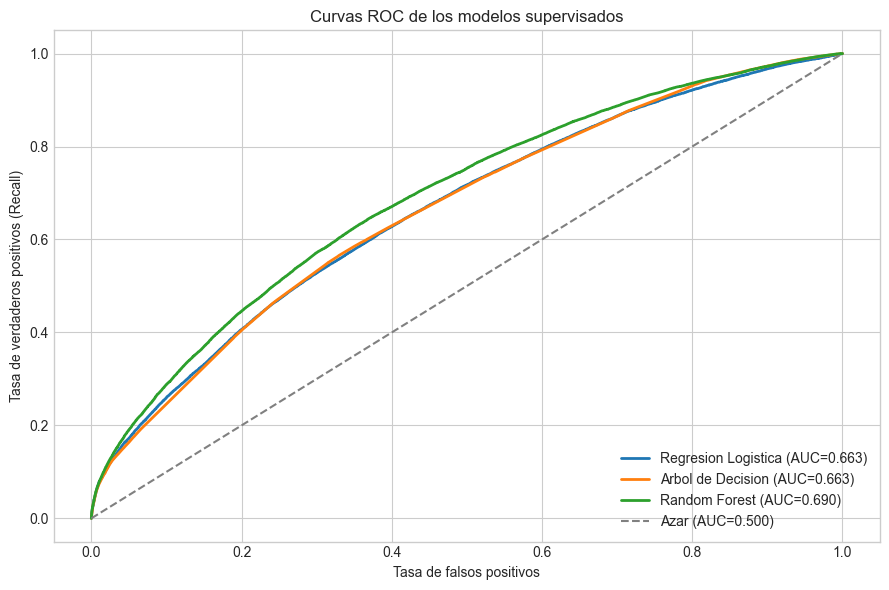

In [23]:
fig, ax = plt.subplots(figsize=(9, 6))
for nombre, valores in predicciones.items():
    fpr, tpr, _ = roc_curve(y_test, valores["prob"])
    auc = roc_auc_score(y_test, valores["prob"])
    ax.plot(fpr, tpr, linewidth=2, label=f"{nombre} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC=0.500)")
ax.set_title("Curvas ROC de los modelos supervisados")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Insight:** un AUC cercano a 0.70 representa discriminación útil pero moderada, no una predicción perfecta. El modelo puede apoyar una priorización, pero la revisión clínica y la incorporación de variables externas, como clima y población DANE, siguen siendo necesarias.

## 8. Comparación visual de métricas

Este gráfico facilita comunicar el compromiso entre precisión, cobertura y discriminación de cada alternativa.

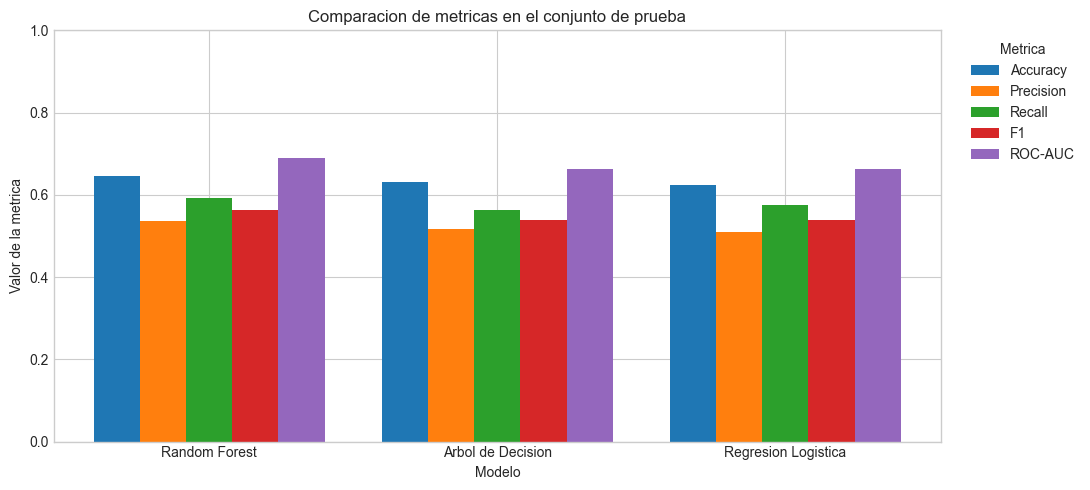

In [24]:
metricas_largas = tabla_metricas.melt(id_vars="Modelo", var_name="Metrica", value_name="Valor")
fig, ax = plt.subplots(figsize=(11, 5))
modelos_grafico = metricas_largas["Modelo"].unique()
metricas_grafico = metricas_largas["Metrica"].unique()
ancho = 0.8 / len(metricas_grafico)
posiciones = np.arange(len(modelos_grafico))
for indice, metrica in enumerate(metricas_grafico):
    valores = metricas_largas[metricas_largas["Metrica"] == metrica].set_index("Modelo").reindex(modelos_grafico)["Valor"]
    ax.bar(posiciones + indice * ancho, valores, width=ancho, label=metrica)
ax.set_xticks(posiciones + ancho * (len(metricas_grafico) - 1) / 2, modelos_grafico)
ax.set_title("Comparacion de metricas en el conjunto de prueba")
ax.set_xlabel("Modelo")
ax.set_ylabel("Valor de la metrica")
ax.set_ylim(0, 1)
ax.legend(title="Metrica", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight:** no existe un ganador universal: la selección depende del costo operativo de cada error. Para una primera versión se recomienda informar el modelo con mayor ROC-AUC y, en paralelo, revisar Recall y Precision antes de fijar un umbral de uso.

## 9. Importancia de variables

Se muestran las variables transformadas más influyentes del mejor modelo según ROC-AUC. En Random Forest la importancia es reducción media de impureza; en modelos lineales se usa el valor absoluto del coeficiente. Estas medidas son asociativas y no deben presentarse como efectos causales.

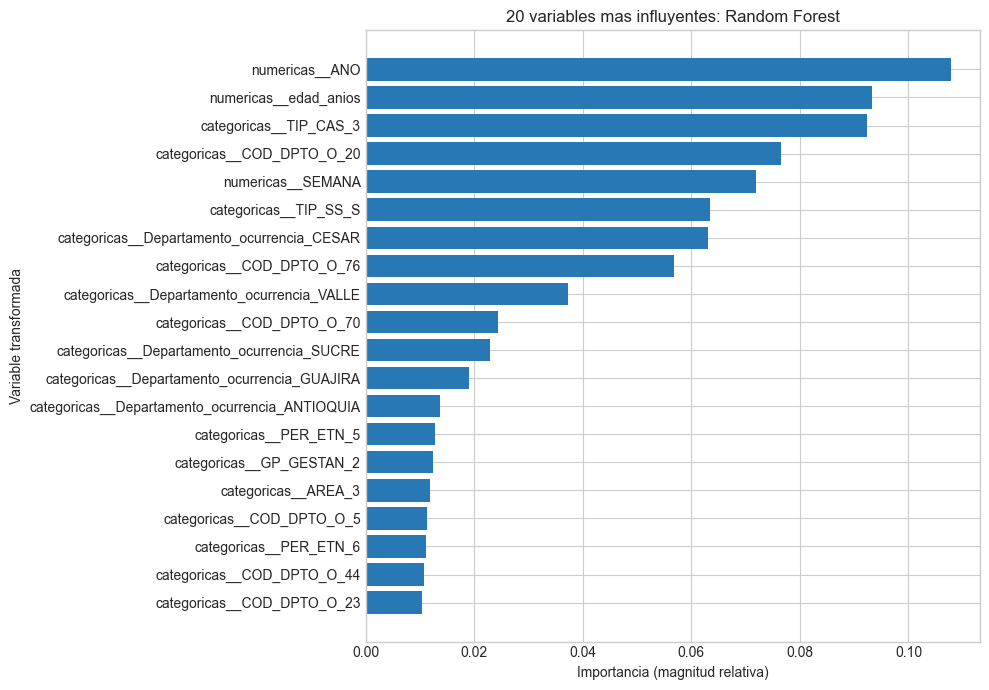

,variable,importancia
0,numericas__ANO,0.107791
2,numericas__edad_anios,0.093263
52,categoricas__TIP_CAS_3,0.092377
10,categoricas__COD_DPTO_O_20,0.076496
1,numericas__SEMANA,0.071952
43,categoricas__TIP_SS_S,0.063404
63,categoricas__Departamento_ocurrencia_CESAR,0.063153
26,categoricas__COD_DPTO_O_76,0.056906
83,categoricas__Departamento_ocurrencia_VALLE,0.037376
24,categoricas__COD_DPTO_O_70,0.024337


In [25]:
mejor_nombre = tabla_metricas.iloc[0]["Modelo"]
mejor_pipeline = ajustes[mejor_nombre].best_estimator_
preparado = mejor_pipeline.named_steps["preprocesamiento"]
modelo_final = mejor_pipeline.named_steps["modelo"]
nombres_variables = preparado.get_feature_names_out()
if hasattr(modelo_final, "feature_importances_"):
    importancias = modelo_final.feature_importances_
else:
    importancias = np.abs(modelo_final.coef_[0])

importancia = pd.DataFrame({"variable": nombres_variables, "importancia": importancias})
importancia = importancia.sort_values("importancia", ascending=False).head(20).sort_values("importancia")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importancia["variable"], importancia["importancia"], color="#2878b5")
ax.set_title(f"20 variables mas influyentes: {mejor_nombre}")
ax.set_xlabel("Importancia (magnitud relativa)")
ax.set_ylabel("Variable transformada")
plt.tight_layout()
plt.show()
display(importancia.sort_values("importancia", ascending=False).head(10))

**Insight:** las variables destacadas indican qué señales utiliza el modelo para separar los registros en este dataset, no cuáles causan hospitalización. Las categorías territoriales deben interpretarse con cuidado porque pueden capturar diferencias de notificación, acceso o calidad del registro.

## 10. Elección, limitaciones y trazabilidad

Se selecciona Random Forest como modelo final preliminar porque obtuvo el mayor ROC-AUC, Recall y F1 en la evaluación aleatoria. Esta decisión debe confirmarse con la evaluación temporal, la calibración y el costo de los errores. Regresión Logística se conserva como alternativa más interpretable, porque permite explicar la dirección y magnitud relativa de sus coeficientes. La decisión final no depende de una sola cifra.

La línea base de clase mayoritaria confirma si el modelo agrega valor frente a predecir siempre la clase dominante; por el desbalance, no basta con comparar Accuracy.

Limitaciones: el objetivo es hospitalización registrada, no gravedad clínica; el dataset no contiene denominadores poblacionales; puede existir deriva temporal entre 2022 y 2025; las variables disponibles pueden reflejar decisiones de notificación; y el test es una evaluación interna. Como mejoras se proponen validación temporal, calibración y ajuste de umbral, datos de población y clima, más variables clínicas disponibles antes de la hospitalización y evaluación externa.

## 10.1. Controles adicionales de calidad y línea base

Se diagnostican duplicados y se compara contra una estrategia que siempre predice la clase mayoritaria. No se eliminan duplicados automáticamente: sin un identificador de paciente, dos filas idénticas podrían corresponder a notificaciones diferentes. Por ello, se conservan en el análisis principal y se reportan como una limitación de calidad de datos, no como evidencia de pacientes repetidos.

In [26]:
diagnostico_modelado = pd.DataFrame({
    "registros": [len(df), len(df.drop_duplicates()), int(df.duplicated().sum())],
    "porcentaje": [100, 100 * len(df.drop_duplicates()) / len(df), 100 * df.duplicated().mean()],
}, index=["Total", "Sin duplicados exactos", "Duplicados exactos"])
display(diagnostico_modelado.round(2))
mayoritaria = int(y_train.mode().iloc[0])
pred_mayoritaria = np.full(len(y_test), mayoritaria, dtype="int8")
linea_base = pd.DataFrame([{
    "Modelo": "Linea base: clase mayoritaria",
    "Accuracy": accuracy_score(y_test, pred_mayoritaria),
    "Precision": precision_score(y_test, pred_mayoritaria, zero_division=0),
    "Recall": recall_score(y_test, pred_mayoritaria, zero_division=0),
    "F1": f1_score(y_test, pred_mayoritaria, zero_division=0),
    "ROC-AUC": 0.5,
}])
comparacion_linea_base = pd.concat([linea_base, tabla_metricas], ignore_index=True)
display(comparacion_linea_base.style.format({c: "{:.4f}" for c in comparacion_linea_base.columns if c != "Modelo"}))

,registros,porcentaje
Total,581071,100.00
Sin duplicados exactos,560617,96.48
Duplicados exactos,20454,3.52


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Linea base: clase mayoritaria,0.6156,0.0000,0.0000,0.0000,0.5000
1,Random Forest,0.6462,0.5361,0.5915,0.5624,0.6900
2,Arbol de Decision,0.6303,0.5175,0.5631,0.5394,0.6634
3,Regresion Logistica,0.6232,0.5087,0.5751,0.5399,0.6630


**Insight:** Accuracy por sí sola puede ser engañosa ante el desbalance. La línea base comprueba que los modelos agregan capacidad de discriminación más allá de predecir siempre la clase dominante.

## 11. Precision-Recall y selección del umbral

La curva ROC compara el ordenamiento global, pero Precision-Recall es especialmente informativa para detectar la clase positiva. El umbral 0.5 no se asume óptimo: se selecciona con una validación interna separada de X_train y luego se aplica una sola vez a X_test.

,Umbral,Precision,Recall,F1
0,0.2000,0.3860,0.9990,0.5569
1,0.2500,0.3927,0.9929,0.5628
2,0.3000,0.4077,0.9679,0.5737
3,0.3500,0.4213,0.9446,0.5827
4,0.4000,0.4406,0.9008,0.5917
5,0.4500,0.4800,0.7868,0.5962
6,0.5000,0.5454,0.5955,0.5694
7,0.5500,0.6012,0.4124,0.4892
8,0.6000,0.6561,0.2699,0.3825
9,0.6500,0.7249,0.1770,0.2846


Resultado del umbral seleccionado en test: {'Umbral seleccionado': 0.45, 'Precision test': 0.4784, 'Recall test': 0.7772, 'F1 test': 0.5923}


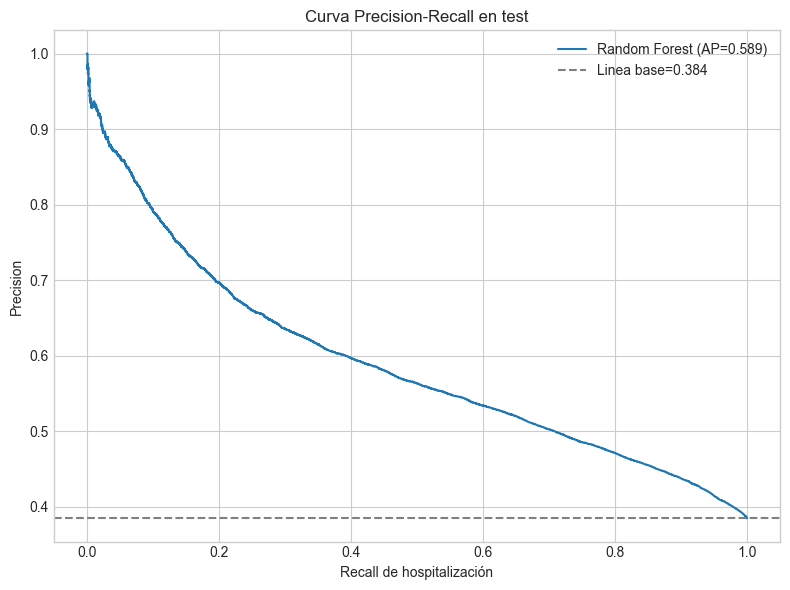

In [27]:
nombre_umbral = mejor_nombre
pipeline_umbral = clone(ajustes[nombre_umbral].best_estimator_)
X_subtrain, X_validacion, y_subtrain, y_validacion = train_test_split(X_train, y_train, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE)
pipeline_umbral.fit(X_subtrain, y_subtrain)
prob_validacion = pipeline_umbral.predict_proba(X_validacion)[:, 1]
umbrales = np.arange(0.20, 0.81, 0.05)
filas_umbral = []
for umbral in umbrales:
    pred_validacion = (prob_validacion >= umbral).astype(int)
    filas_umbral.append({"Umbral": umbral, "Precision": precision_score(y_validacion, pred_validacion, zero_division=0), "Recall": recall_score(y_validacion, pred_validacion, zero_division=0), "F1": f1_score(y_validacion, pred_validacion, zero_division=0)})
tabla_umbral = pd.DataFrame(filas_umbral)
umbral_elegido = float(tabla_umbral.loc[tabla_umbral["F1"].idxmax(), "Umbral"])
pred_test_umbral = (predicciones[nombre_umbral]["prob"] >= umbral_elegido).astype(int)
resultado_umbral = {"Umbral seleccionado": umbral_elegido, "Precision test": precision_score(y_test, pred_test_umbral, zero_division=0), "Recall test": recall_score(y_test, pred_test_umbral, zero_division=0), "F1 test": f1_score(y_test, pred_test_umbral, zero_division=0)}
display(tabla_umbral.style.format({c: "{:.4f}" for c in tabla_umbral.columns}))
print("Resultado del umbral seleccionado en test:", {k: round(v, 4) if isinstance(v, float) else v for k, v in resultado_umbral.items()})
precision_curve, recall_curve, _ = precision_recall_curve(y_test, predicciones[nombre_umbral]["prob"])
average_precision = average_precision_score(y_test, predicciones[nombre_umbral]["prob"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_curve, precision_curve, label=f"{nombre_umbral} (AP={average_precision:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"Linea base={y_test.mean():.3f}")
ax.set_title("Curva Precision-Recall en test")
ax.set_xlabel("Recall de hospitalización")
ax.set_ylabel("Precision")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** un umbral menor puede aumentar Recall y reducir falsos negativos, pero genera más falsos positivos. El umbral se selecciona en una validación interna y no mirando el resultado de test.

## 12. Deriva temporal y validación hacia periodos posteriores

La división aleatoria puede ser optimista cuando hay cambios entre 2022 y 2025. Se reporta la tasa de hospitalización por año y se reserva el último año disponible para una evaluación adicional.

In [28]:
df_temporal = df.copy()
df_temporal["ano_modelo"] = pd.to_numeric(df_temporal["ANO"], errors="coerce")
resumen_temporal = df_temporal.groupby("ano_modelo")[TARGET].agg(registros="size", tasa_hospitalizacion="mean").reset_index()
resumen_temporal["tasa_hospitalizacion"] *= 100
display(resumen_temporal.style.format({"tasa_hospitalizacion": "{:.2f}"}))
anos_validos = sorted(X["ANO"].dropna().unique())
if len(anos_validos) >= 2:
    ano_prueba = anos_validos[-1]
    mascara_train_temporal = X["ANO"] < ano_prueba
    mascara_test_temporal = X["ANO"] == ano_prueba
    X_train_temporal, X_test_temporal = X.loc[mascara_train_temporal], X.loc[mascara_test_temporal]
    y_train_temporal, y_test_temporal = y.loc[mascara_train_temporal], y.loc[mascara_test_temporal]
    modelo_temporal = clone(ajustes[mejor_nombre].best_estimator_)
    modelo_temporal.fit(X_train_temporal, y_train_temporal)
    prob_temporal = modelo_temporal.predict_proba(X_test_temporal)[:, 1]
    pred_temporal = (prob_temporal >= 0.5).astype(int)
    resultado_temporal = pd.DataFrame([{"Periodo de prueba": int(ano_prueba), "Registros train": len(X_train_temporal), "Registros test": len(X_test_temporal), "ROC-AUC": roc_auc_score(y_test_temporal, prob_temporal), "Precision": precision_score(y_test_temporal, pred_temporal, zero_division=0), "Recall": recall_score(y_test_temporal, pred_temporal, zero_division=0), "F1": f1_score(y_test_temporal, pred_temporal, zero_division=0)}])
    display(resultado_temporal.style.format({"ROC-AUC": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}))
    resultado_comparacion = pd.DataFrame([
        {"Evaluacion": "Split aleatorio", "ROC-AUC": tabla_metricas.iloc[0]["ROC-AUC"], "Precision": tabla_metricas.iloc[0]["Precision"], "Recall": tabla_metricas.iloc[0]["Recall"], "F1": tabla_metricas.iloc[0]["F1"]},
        {"Evaluacion": "Split temporal", "ROC-AUC": resultado_temporal.iloc[0]["ROC-AUC"], "Precision": resultado_temporal.iloc[0]["Precision"], "Recall": resultado_temporal.iloc[0]["Recall"], "F1": resultado_temporal.iloc[0]["F1"]},
    ])
    print("Comparacion del modelo final entre evaluacion aleatoria y temporal:")
    display(resultado_comparacion.style.format({c: "{:.4f}" for c in resultado_comparacion.columns if c != "Evaluacion"}))

,ano_modelo,registros,tasa_hospitalizacion
0,2022,63076,52.82
1,2023,113314,44.59
2,2024,292384,33.59
3,2025,112297,36.78


,Periodo de prueba,Registros train,Registros test,ROC-AUC,Precision,Recall,F1
0,2025,468774,112297,0.6691,0.4935,0.5958,0.5399


Comparacion del modelo final entre evaluacion aleatoria y temporal:


,Evaluacion,ROC-AUC,Precision,Recall,F1
0,Split aleatorio,0.6900,0.5361,0.5915,0.5624
1,Split temporal,0.6691,0.4935,0.5958,0.5399


**Interpretación:** la tabla compara el desempeño del modelo final en una partición aleatoria y en un periodo posterior no utilizado para entrenar. Si el resultado temporal cae frente al aleatorio, existe evidencia de deriva o menor generalización hacia datos futuros; en ese caso, el AUC aleatorio no debe presentarse como garantía de desempeño operativo.

## 13. Calibración e interpretabilidad por permutación

ROC-AUC mide ordenamiento, pero no garantiza que una probabilidad de 0.70 corresponda aproximadamente a un 70 % de hospitalizaciones. También se calcula importancia por permutación sobre una muestra de test.

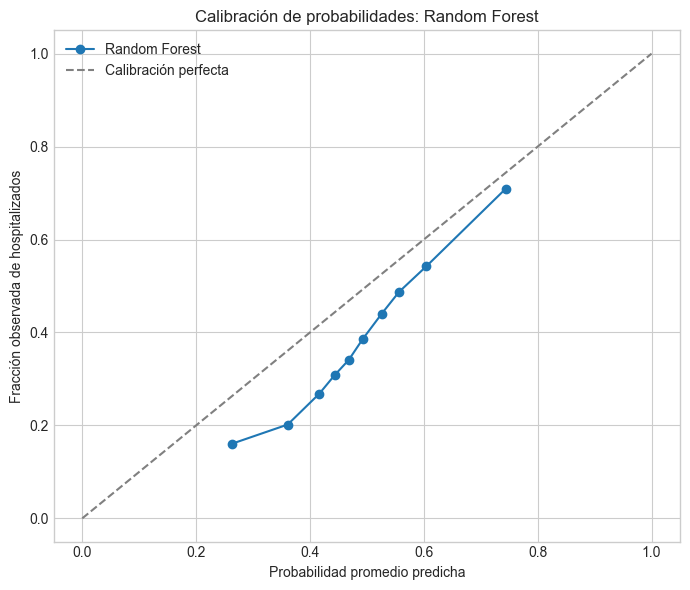

Brier score de Random Forest: 0.2226 (menor es mejor)


,variable,disminucion_auc_promedio,desviacion
3,COD_DPTO_O,0.045499,0.002205
11,TIP_CAS,0.039953,0.001397
12,Departamento_ocurrencia,0.036065,0.001106
1,ANO,0.031633,0.002821
5,TIP_SS,0.018697,0.001321
13,edad_anios,0.011214,0.001102
6,PER_ETN,0.006787,0.000174
0,SEMANA,0.006455,0.001079
4,AREA,0.006330,0.000513
10,GP_GESTAN,0.002317,0.000141


In [29]:
prob_mejor = predicciones[mejor_nombre]["prob"]
fraccion_calibrada, promedio_calibrado = calibration_curve(y_test, prob_mejor, n_bins=10, strategy="quantile")
brier = brier_score_loss(y_test, prob_mejor)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(promedio_calibrado, fraccion_calibrada, marker="o", label=mejor_nombre)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibración perfecta")
ax.set_title(f"Calibración de probabilidades: {mejor_nombre}")
ax.set_xlabel("Probabilidad promedio predicha")
ax.set_ylabel("Fracción observada de hospitalizados")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Brier score de {mejor_nombre}: {brier:.4f} (menor es mejor)")
rng = np.random.RandomState(RANDOM_STATE)
indices_perm = rng.choice(len(X_test), size=min(10000, len(X_test)), replace=False)
perm = permutation_importance(ajustes[mejor_nombre].best_estimator_, X_test.iloc[indices_perm], y_test.iloc[indices_perm], scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
importancia_perm = pd.DataFrame({"variable": X_test.columns, "disminucion_auc_promedio": perm.importances_mean, "desviacion": perm.importances_std}).sort_values("disminucion_auc_promedio", ascending=False).head(15)
display(importancia_perm)

**Insight:** las importancias muestran señales asociadas con el desempeño predictivo, no causas de hospitalización. La calibración y la importancia por permutación complementan la curva ROC y evitan interpretar una única métrica como evidencia suficiente.

## 14. Síntesis final para el informe

- La clase positiva es hospitalización registrada (`PAC_HOS = 1`), no diagnóstico, gravedad ni tasa poblacional.
- Se compararon los tres modelos obligatorios; Random Forest se selecciona preliminarmente por su mejor ROC-AUC, Recall y F1 en la partición aleatoria, sujeto a la validación temporal.
- El pipeline evita ajustar imputación, codificación y escalamiento con el conjunto de prueba.
- La evaluación aleatoria se complementa con la evaluación temporal por la posible deriva entre años; la diferencia entre ambas debe reportarse en el informe.
- La línea base de clase mayoritaria se utiliza como referencia y el umbral debe definirse según el costo de falsos negativos y falsos positivos.
- Se requieren datos nuevos, variables clínicas disponibles antes del evento, población DANE, clima y validación externa para un uso operativo.

In [ ]:
# Auditoria final de requisitos.
assert len(ajustes) == 3
assert set(["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).issubset(tabla_metricas.columns)
assert all("modelo" in busqueda.best_estimator_.named_steps for busqueda in ajustes.values())
assert all(busqueda.cv == 3 for busqueda in ajustes.values())
assert "Linea base: clase mayoritaria" in comparacion_linea_base["Modelo"].values
assert "edad_anios" in X.columns and "EDAD" not in X.columns and "UNI_MED" not in X.columns
assert 0 < average_precision <= 1
assert 0 < umbral_elegido < 1
assert "resultado_comparacion" in globals()
print("Validacion final OK")
print(f"Modelo recomendado provisionalmente por ROC-AUC: {mejor_nombre}")
print("El conjunto de prueba solo se utilizo para la evaluacion final.")

Validacion final OK
Modelo recomendado provisionalmente por ROC-AUC: Random Forest
El conjunto de prueba solo se utilizo para la evaluacion final.
